# 🏭 Manufacturing Equipment Output Prediction

## Project Overview

This project focuses on predicting the hourly production output of a plastic injection molding machine using machine operating parameters and production-related factors.

The objective is to build a supervised machine learning regression model that can predict `Parts_Per_Hour` and provide insights into the factors associated with manufacturing output.

### Business Problem

Manufacturing companies need to maintain efficient machine operation and production planning. Variations in machine settings, operating conditions, material properties, and other factors can affect production output.

This project uses historical manufacturing data to develop a predictive model for estimating the number of parts produced per hour.

### Project Objective

The main objective is to:

- Analyze manufacturing equipment data.
- Identify relationships between machine parameters and production output.
- Preprocess the dataset appropriately.
- Build a Linear Regression model to predict `Parts_Per_Hour`.
- Evaluate the model using regression metrics.
- Interpret the model results from a manufacturing perspective.

### Target Variable

**`Parts_Per_Hour`** — the number of plastic parts produced by the machine per hour.

### Machine Learning Type

**Supervised Learning → Regression**

# 1. Importing Libraries

In [31]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

from sklearn.impute import SimpleImputer

print("All required libraries are imported..!!")

All required libraries are imported..!!


In [2]:
# Visualization settings

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# 2. Load the Dataset

In [4]:
df = pd.read_csv("manufacturing_dataset_1000_samples.csv")

print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Dataset loaded successfully.
Number of rows: 1000
Number of columns: 19


In [5]:
# Display the first five records

display(df.head())

,Timestamp,Injection_Temperature,Injection_Pressure,Cycle_Time,Cooling_Time,Material_Viscosity,Ambient_Temperature,Machine_Age,Operator_Experience,Maintenance_Hours,Shift,Machine_Type,Material_Grade,Day_of_Week,Temperature_Pressure_Ratio,Total_Cycle_Time,Efficiency_Score,Machine_Utilization,Parts_Per_Hour
0,2023-01-01 00:00:00,221.0,136.0,28.7,13.6,375.5,28.0,3.8,11.2,64,Evening,Type_B,Economy,Thursday,1.625,42.3,0.063,0.510,36.5
1,2023-01-01 01:00:00,213.3,128.9,34.5,14.0,215.8,22.6,6.8,6.3,58,Night,Type_A,Standard,Wednesday,1.655,48.5,0.037,0.389,29.9
2,2023-01-01 02:00:00,222.8,115.9,19.9,9.5,307.0,25.3,4.2,9.6,47,Day,Type_A,Standard,Monday,1.922,29.4,0.061,0.551,56.9
3,2023-01-01 03:00:00,233.3,105.3,39.2,13.1,137.8,26.0,9.2,8.6,49,Evening,Type_A,Premium,Saturday,2.215,52.3,0.054,0.293,31.0
4,2023-01-01 04:00:00,212.2,125.5,45.0,9.9,298.2,23.6,6.2,23.0,49,Night,Type_B,Premium,Monday,1.691,54.9,0.145,0.443,15.0


In [6]:
# Display the dataset dimensions

print(f"Dataset shape: {df.shape}")

Dataset shape: (1000, 19)


# 3. Dataset Overview

In [7]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Timestamp                   1000 non-null   object 
 1   Injection_Temperature       1000 non-null   float64
 2   Injection_Pressure          1000 non-null   float64
 3   Cycle_Time                  1000 non-null   float64
 4   Cooling_Time                1000 non-null   float64
 5   Material_Viscosity          980 non-null    float64
 6   Ambient_Temperature         980 non-null    float64
 7   Machine_Age                 1000 non-null   float64
 8   Operator_Experience         980 non-null    float64
 9   Maintenance_Hours           1000 non-null   int64  
 10  Shift                       1000 non-null   object 
 11  Machine_Type                1000 non-null   object 
 12  Material_Grade              1000 non-null   object 
 13  Day_of_Week                 1000 n

In [8]:
# Display summary statistics for numerical variables

display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Injection_Temperature,1000.0,215.315900,11.995507,180.000,207.20000,215.3000,222.80000,300.000
Injection_Pressure,1000.0,116.075000,14.667246,80.000,105.90000,115.9500,125.92500,150.000
Cycle_Time,1000.0,35.851700,8.353490,16.300,28.80000,36.8500,45.00000,60.000
Cooling_Time,1000.0,11.923200,2.304290,8.000,10.27500,11.9000,13.50000,19.900
Material_Viscosity,980.0,251.630714,73.348695,104.600,200.90000,242.7000,295.30000,1000.000
Ambient_Temperature,980.0,22.941224,2.773712,18.000,20.80000,22.9000,25.10000,28.000
Machine_Age,1000.0,7.855900,3.900798,1.000,4.70000,7.9000,11.10000,15.000
Operator_Experience,980.0,30.795204,27.684769,1.000,9.80000,22.1000,43.42500,120.000
Maintenance_Hours,1000.0,50.580000,16.014558,26.000,45.00000,50.0000,55.00000,500.000
Temperature_Pressure_Ratio,1000.0,1.885852,0.274323,1.286,1.68375,1.8495,2.04425,2.843


In [9]:
# Display all column names

for i, column in enumerate(df.columns, start=1):
    print(f"{i}. {column}")

1. Timestamp
2. Injection_Temperature
3. Injection_Pressure
4. Cycle_Time
5. Cooling_Time
6. Material_Viscosity
7. Ambient_Temperature
8. Machine_Age
9. Operator_Experience
10. Maintenance_Hours
11. Shift
12. Machine_Type
13. Material_Grade
14. Day_of_Week
15. Temperature_Pressure_Ratio
16. Total_Cycle_Time
17. Efficiency_Score
18. Machine_Utilization
19. Parts_Per_Hour


# 4. Data Quality Assessment

In [10]:
# Check for missing values in each column

missing_values = df.isnull().sum()

display(missing_values[missing_values > 0])

Material_Viscosity     20
Ambient_Temperature    20
Operator_Experience    20
dtype: int64

In [11]:
# Check for duplicate rows

duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count}")

Number of duplicate rows: 0


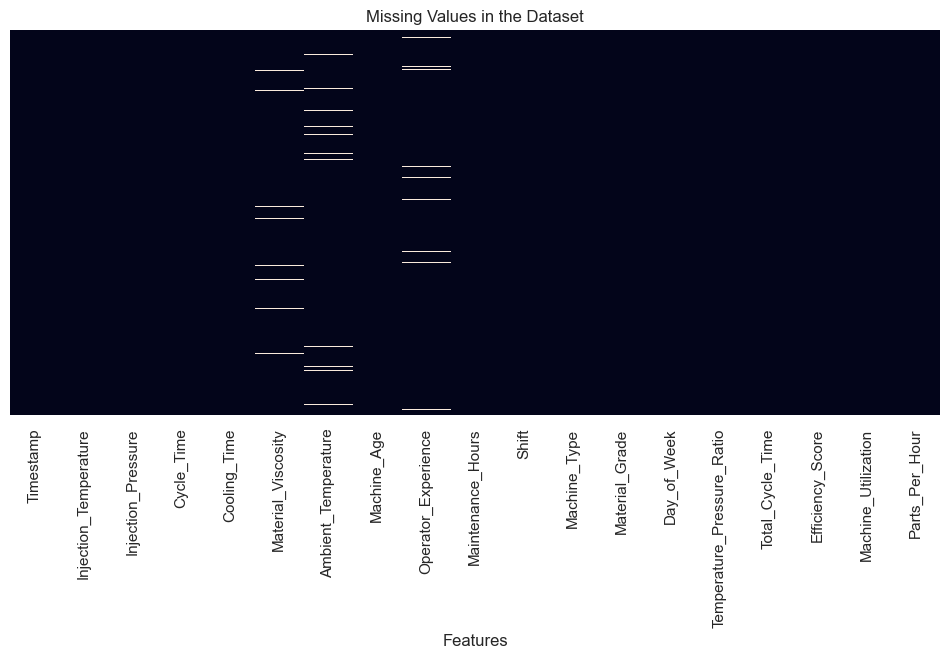

In [12]:
# Visualize missing values

plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values in the Dataset")
plt.xlabel("Features")
plt.show()

#  5. Exploratory Data Analysis (EDA)

## 5.1. Target Variable Analysis


In [13]:
# Summary statistics of the target variable

display(df["Parts_Per_Hour"].describe())

count    1000.000000
mean       29.298100
std        11.955497
min         5.000000
25%        17.500000
50%        28.200000
75%        38.000000
max        68.600000
Name: Parts_Per_Hour, dtype: float64

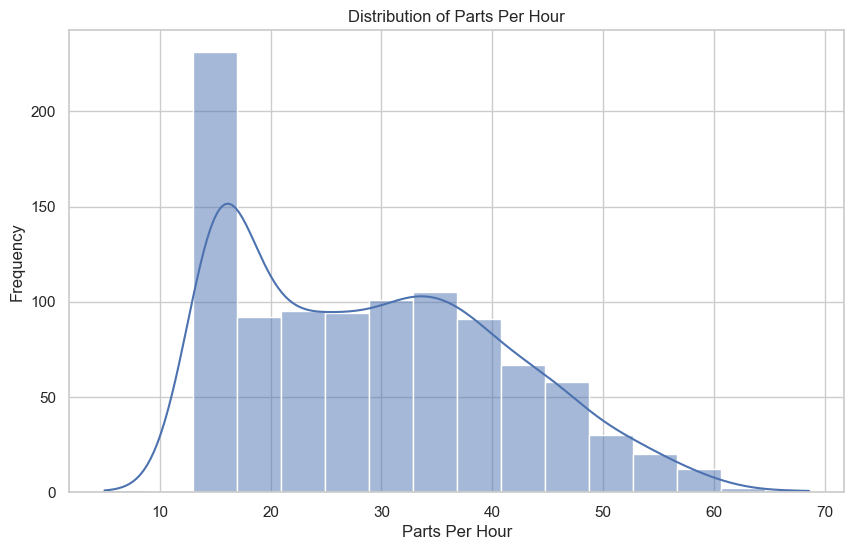

In [14]:
# Distribution of Parts Per Hour

plt.figure(figsize=(10, 6))

sns.histplot(
    df["Parts_Per_Hour"],
    kde=True
)

plt.title("Distribution of Parts Per Hour")
plt.xlabel("Parts Per Hour")
plt.ylabel("Frequency")
plt.show()

The dataset contains 1000 manufacturing records with 19 columns. Most features are numerical, while Shift, Machine_Type, Material_Grade, and Day_of_Week are categorical. The target variable is Parts_Per_Hour.

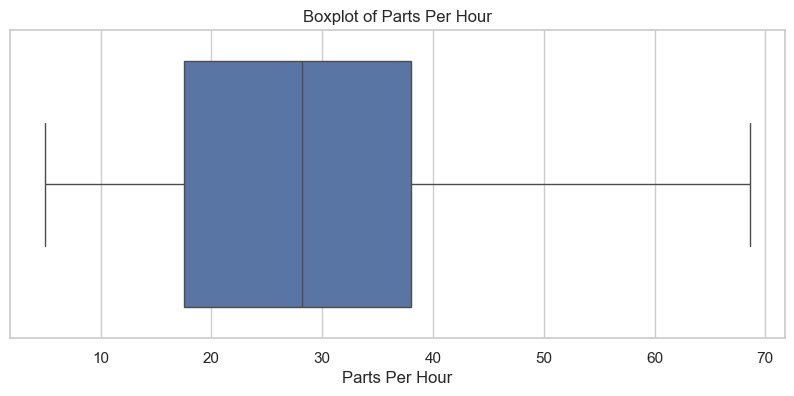

In [15]:
# Boxplot of Parts Per Hour

plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Parts_Per_Hour"])

plt.title("Boxplot of Parts Per Hour")
plt.xlabel("Parts Per Hour")
plt.show()

### Observation

The distribution of `Parts_Per_Hour` shows considerable variation in hourly production output. Most observations are concentrated in the lower-to-middle production range, with another noticeable concentration around the higher production range.

The boxplot shows a median production output of approximately 28 parts per hour, while the middle 50% of observations fall roughly between 18 and 38 parts per hour. The distribution extends across a wider range of production levels, indicating differences in machine output across observations.

No individual outlier points are visibly identified by the boxplot.

## 5.2. Numerical Features Analysis

In [16]:
# Identify numerical features

numerical_features = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical features:")
for feature in numerical_features:
    print("-", feature)

Numerical features:
- Injection_Temperature
- Injection_Pressure
- Cycle_Time
- Cooling_Time
- Material_Viscosity
- Ambient_Temperature
- Machine_Age
- Operator_Experience
- Maintenance_Hours
- Temperature_Pressure_Ratio
- Total_Cycle_Time
- Efficiency_Score
- Machine_Utilization
- Parts_Per_Hour


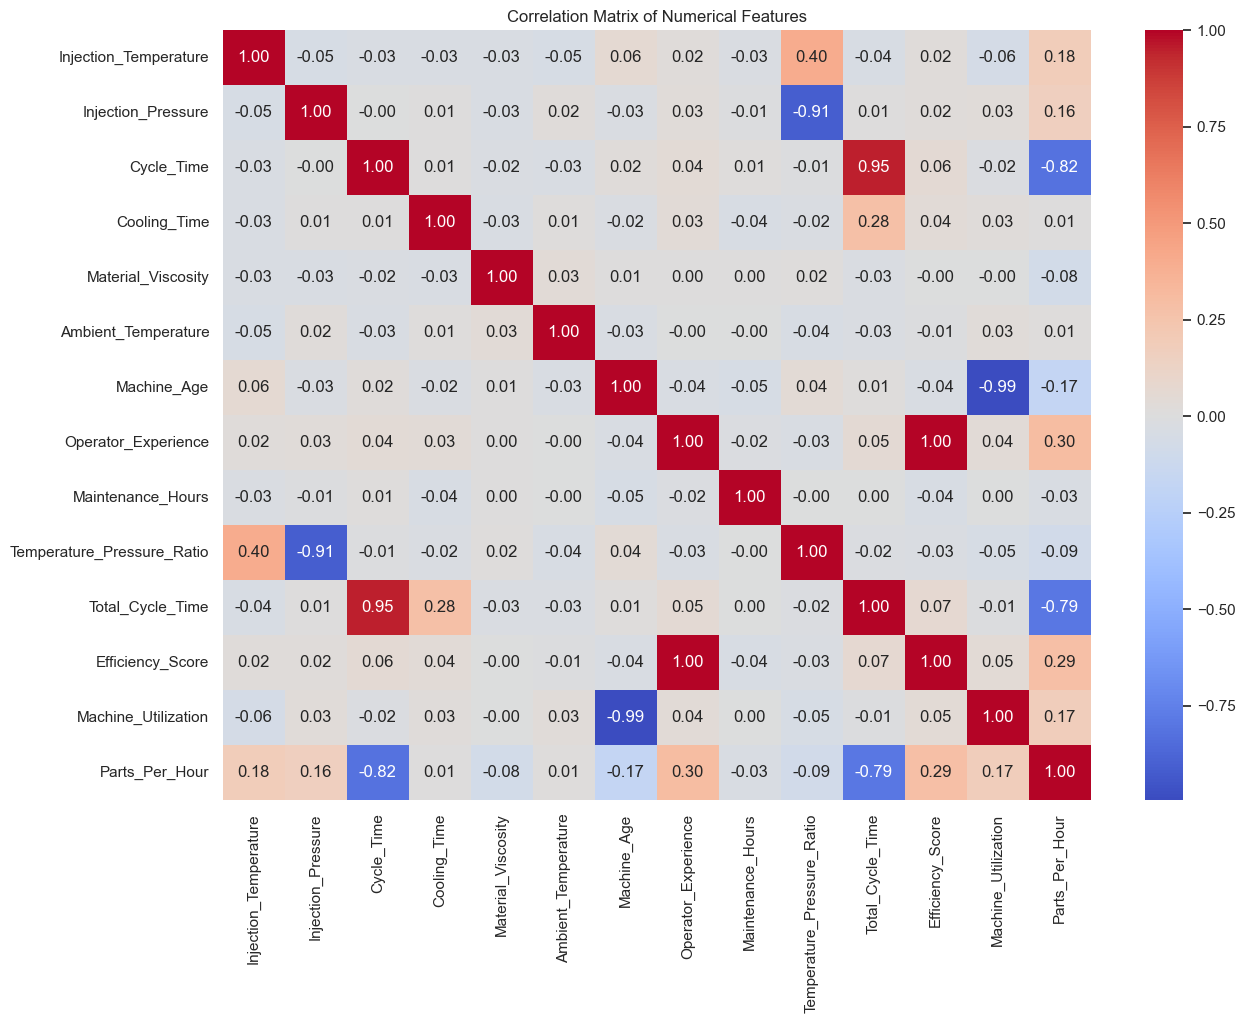

In [17]:
# Correlation matrix for numerical features

correlation_matrix = df[numerical_features].corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()

In [18]:
# Correlation of numerical features with Parts_Per_Hour

target_correlation = (
    correlation_matrix["Parts_Per_Hour"]
    .sort_values(ascending=False)
)

display(target_correlation)

Parts_Per_Hour                1.000000
Operator_Experience           0.300891
Efficiency_Score              0.286794
Injection_Temperature         0.184353
Machine_Utilization           0.174573
Injection_Pressure            0.160362
Ambient_Temperature           0.011812
Cooling_Time                  0.006215
Maintenance_Hours            -0.032955
Material_Viscosity           -0.080575
Temperature_Pressure_Ratio   -0.086113
Machine_Age                  -0.174518
Total_Cycle_Time             -0.792862
Cycle_Time                   -0.819446
Name: Parts_Per_Hour, dtype: float64

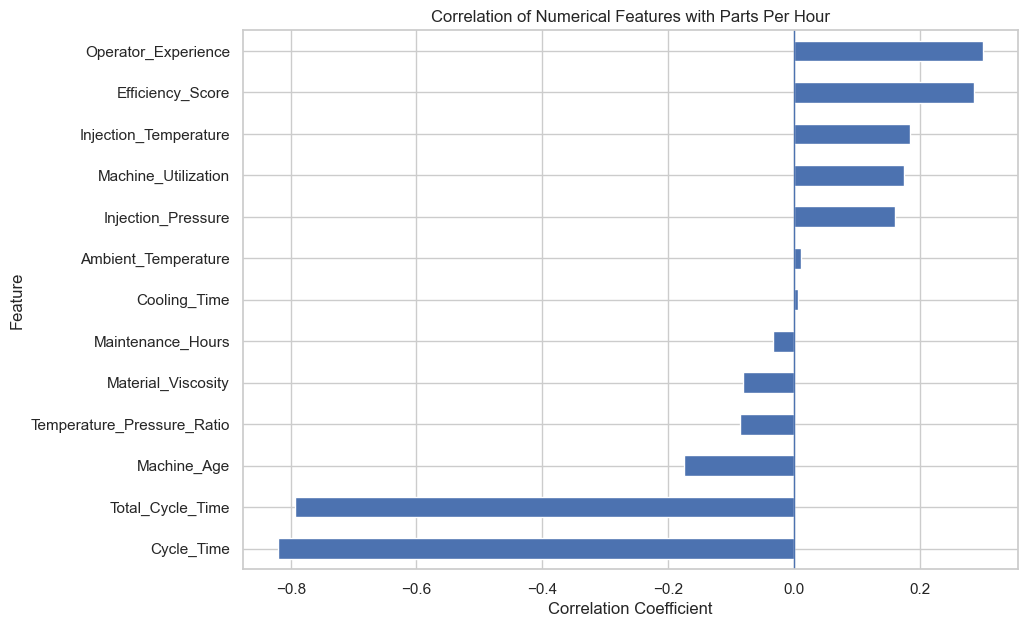

In [19]:
# Correlation of numerical features with Parts_Per_Hour

target_corr = (
    correlation_matrix["Parts_Per_Hour"]
    .drop("Parts_Per_Hour")
    .sort_values()
)

plt.figure(figsize=(10, 7))

target_corr.plot(kind="barh")

plt.title("Correlation of Numerical Features with Parts Per Hour")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Feature")

plt.axvline(0, linewidth=1)

plt.show()

### KEY OBSERVATIONS
The correlation analysis shows that `Cycle_Time` has the strongest negative relationship with `Parts_Per_Hour` (r = -0.819), followed by `Total_Cycle_Time` (r = -0.793).

`Operator_Experience` (r = 0.301) and `Efficiency_Score` (r = 0.287) show moderate positive relationships with production output.

`Injection_Temperature`, `Machine_Utilization`, and `Injection_Pressure` show weaker positive relationships with `Parts_Per_Hour`.

The correlation matrix also indicates strong relationships among some predictor variables, particularly between `Cycle_Time` and `Total_Cycle_Time` (r = 0.95). This suggests potential multicollinearity that should be considered during model development and feature interpretation.

In [ ]:
# Remove Timestamp column
df = df.drop("Timestamp", axis=1)

df.head()

,Injection_Temperature,Injection_Pressure,Cycle_Time,Cooling_Time,Material_Viscosity,Ambient_Temperature,Machine_Age,Operator_Experience,Maintenance_Hours,Shift,Machine_Type,Material_Grade,Day_of_Week,Temperature_Pressure_Ratio,Total_Cycle_Time,Efficiency_Score,Machine_Utilization,Parts_Per_Hour
0,221.0,136.0,28.7,13.6,375.5,28.0,3.8,11.2,64,Evening,Type_B,Economy,Thursday,1.625,42.3,0.063,0.510,36.5
1,213.3,128.9,34.5,14.0,215.8,22.6,6.8,6.3,58,Night,Type_A,Standard,Wednesday,1.655,48.5,0.037,0.389,29.9
2,222.8,115.9,19.9,9.5,307.0,25.3,4.2,9.6,47,Day,Type_A,Standard,Monday,1.922,29.4,0.061,0.551,56.9
3,233.3,105.3,39.2,13.1,137.8,26.0,9.2,8.6,49,Evening,Type_A,Premium,Saturday,2.215,52.3,0.054,0.293,31.0
4,212.2,125.5,45.0,9.9,298.2,23.6,6.2,23.0,49,Night,Type_B,Premium,Monday,1.691,54.9,0.145,0.443,15.0


## 5.3 Categorical Feature Analysis

In [20]:
# Display unique categories for categorical features

categorical_features = [
    "Shift",
    "Machine_Type",
    "Material_Grade",
    "Day_of_Week"
]

for feature in categorical_features:
    print(f"\n{feature}:")
    print(df[feature].value_counts())


Shift:
Shift
Day        517
Evening    277
Night      206
Name: count, dtype: int64

Machine_Type:
Machine_Type
Type_A    384
Type_B    347
Type_C    269
Name: count, dtype: int64

Material_Grade:
Material_Grade
Standard    591
Premium     210
Economy     199
Name: count, dtype: int64

Day_of_Week:
Day_of_Week
Friday       168
Wednesday    155
Thursday     150
Saturday     141
Tuesday      138
Monday       136
Sunday       112
Name: count, dtype: int64


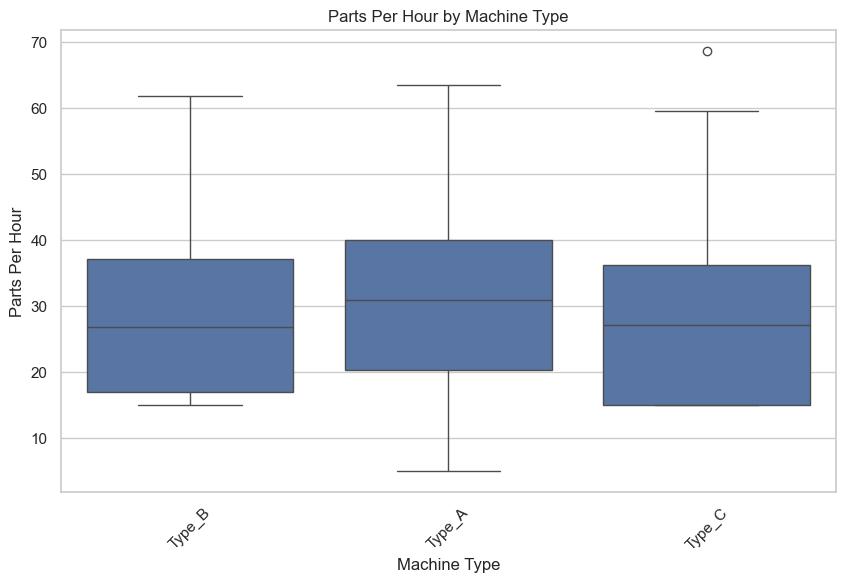

In [21]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Machine_Type",
    y="Parts_Per_Hour"
)

plt.title("Parts Per Hour by Machine Type")
plt.xlabel("Machine Type")
plt.ylabel("Parts Per Hour")
plt.xticks(rotation=45)

plt.show()

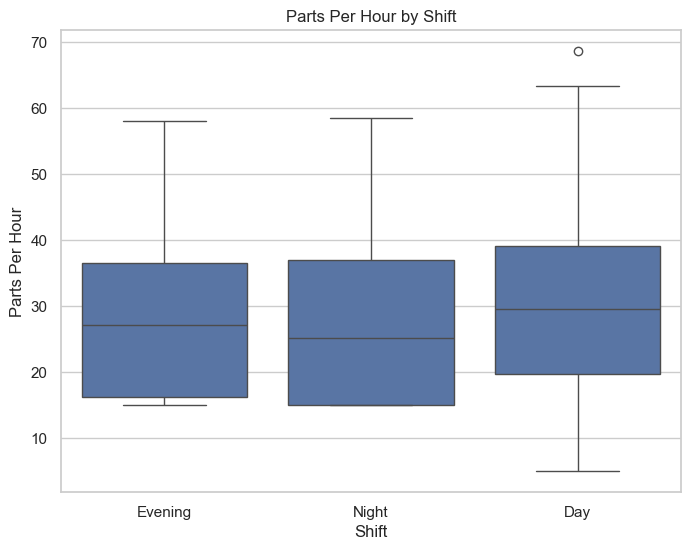

In [22]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    data=df,
    x="Shift",
    y="Parts_Per_Hour"
)

plt.title("Parts Per Hour by Shift")
plt.xlabel("Shift")
plt.ylabel("Parts Per Hour")

plt.show()

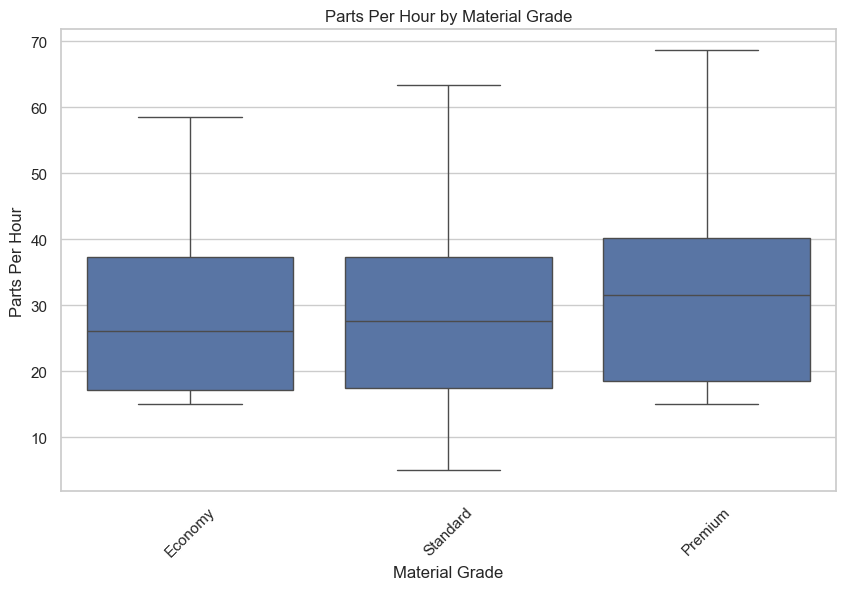

In [23]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Material_Grade",
    y="Parts_Per_Hour"
)

plt.title("Parts Per Hour by Material Grade")
plt.xlabel("Material Grade")
plt.ylabel("Parts Per Hour")
plt.xticks(rotation=45)

plt.show()

### Key observations
The categorical analysis shows some variation in production output across machine types, shifts, and material grades.

- **Machine Type:** Type A shows a slightly higher median `Parts_Per_Hour` than Type B and Type C. The distributions of the three machine types overlap considerably, indicating that machine type alone does not completely determine production output. Type C also contains a high-output observation near 69 parts per hour.

- **Shift:** The Day shift has a slightly higher median production output than the Evening and Night shifts. However, the distributions overlap substantially across all three shifts, suggesting that the differences between shifts are relatively moderate. A high-output observation is also visible for the Day shift.

- **Material Grade:** Premium material shows the highest median `Parts_Per_Hour`, followed by Standard and Economy grades. The distributions still overlap, indicating that material grade may be associated with production output but is not the only factor influencing it.

Overall, the categorical variables show differences in production output across their groups, but the substantial overlap between categories suggests that multiple manufacturing and operational factors contribute to hourly production.

# 6. Data Preprocessing

In [24]:
# Separate features and target variable

X = df.drop(columns=["Parts_Per_Hour"])
y = df["Parts_Per_Hour"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1000, 18)
Target shape: (1000,)


In [25]:
# Convert Timestamp to datetime

df["Timestamp"] = pd.to_datetime(df["Timestamp"])

print(df["Timestamp"].dtype)

datetime64[ns]


In [26]:
# Extract hour from Timestamp

df["Hour"] = df["Timestamp"].dt.hour

display(df[["Timestamp", "Hour"]].head())

,Timestamp,Hour
0,2023-01-01 00:00:00,0
1,2023-01-01 01:00:00,1
2,2023-01-01 02:00:00,2
3,2023-01-01 03:00:00,3
4,2023-01-01 04:00:00,4


In [27]:
# Remove the original Timestamp column

df = df.drop(columns=["Timestamp"])

print("Timestamp removed. New shape:", df.shape)

Timestamp removed. New shape: (1000, 19)


In [28]:
# Recreate features and target after timestamp processing

X = df.drop(columns=["Parts_Per_Hour"])
y = df["Parts_Per_Hour"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1000, 18)
Target shape: (1000,)


## 6.1 Train-Test-Split

In [29]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (800, 18)
Testing feature shape: (200, 18)
Training target shape: (800,)
Testing target shape: (200,)


In [30]:
# Update numerical features after adding the Hour feature

numerical_features = [
    feature for feature in numerical_features
    if feature in X_train.columns
]

if "Hour" in X_train.columns and "Hour" not in numerical_features:
    numerical_features.append("Hour")

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Injection_Temperature', 'Injection_Pressure', 'Cycle_Time', 'Cooling_Time', 'Material_Viscosity', 'Ambient_Temperature', 'Machine_Age', 'Operator_Experience', 'Maintenance_Hours', 'Temperature_Pressure_Ratio', 'Total_Cycle_Time', 'Efficiency_Score', 'Machine_Utilization', 'Hour']
Categorical features: ['Shift', 'Machine_Type', 'Material_Grade', 'Day_of_Week']


In [32]:
# Preprocessing for numerical features
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore"))
])

print("Numerical and categorical preprocessing transformers created.")

Numerical and categorical preprocessing transformers created.


In [33]:
# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [34]:
# Create the Linear Regression pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

print("Linear Regression pipeline created successfully.")

Linear Regression pipeline created successfully.


### Training the data

In [35]:
# Train the Linear Regression model
model.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


### Testing the model

In [36]:
# Generate predictions on the test set
y_pred = model.predict(X_test)

print("Predictions generated successfully.")
print("First 10 predictions:")
print(y_pred[:10])

Predictions generated successfully.
First 10 predictions:
[19.93598612 44.4287589  34.08753373 39.68067895 18.34945969 20.41398317
 33.50085541 14.09168252 28.02050379 32.37107296]


In [37]:
# Evaluate model performance

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Performance:")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.3f}")

Model Performance:
MAE  : 2.72
MSE  : 12.32
RMSE : 3.51
R²   : 0.906


### MODEL EVALUATION
The Linear Regression model achieved an R² score of 0.906, indicating that the model explains approximately 90.6% of the variation in `Parts_Per_Hour` on the test set.

The model has an MAE of 2.72 parts per hour and an RMSE of 3.51 parts per hour, indicating relatively small prediction errors compared with the overall range of production output.

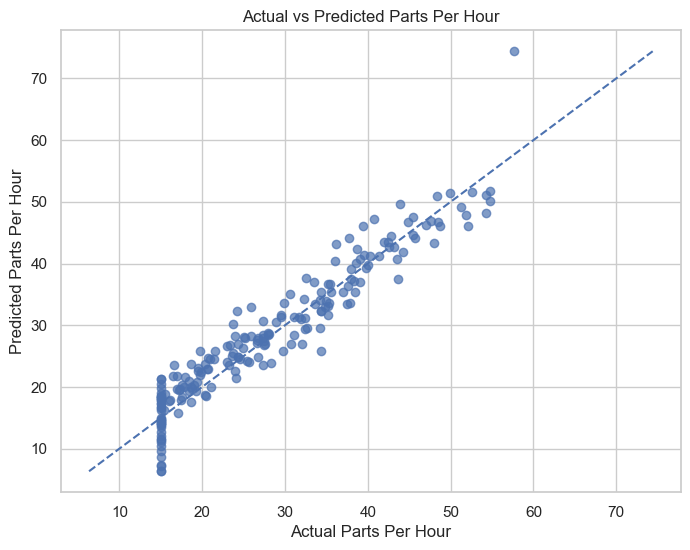

In [38]:
# Actual vs Predicted Values

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

# Perfect prediction line
min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Parts Per Hour")
plt.ylabel("Predicted Parts Per Hour")
plt.title("Actual vs Predicted Parts Per Hour")
plt.show()

### Observation

The actual versus predicted plot shows that most observations are positioned close to the reference line, indicating good agreement between the actual and predicted production output.

A small number of observations show larger deviations from the reference line, representing cases where the model has higher prediction error.

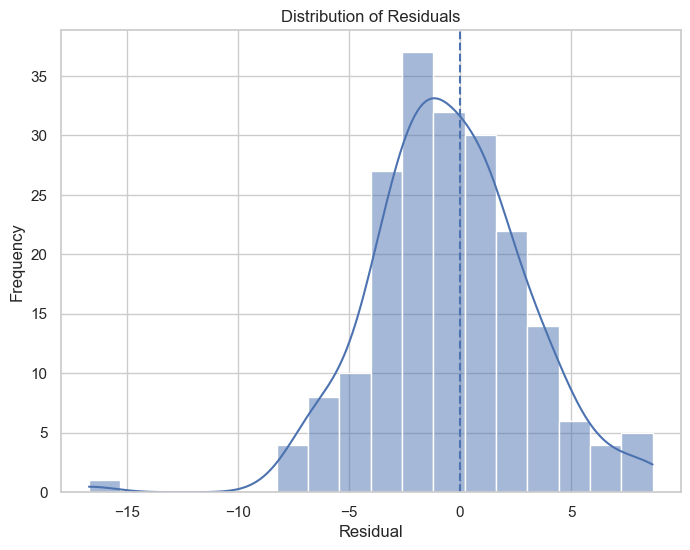

In [39]:
# Calculate residuals
residuals = y_test - y_pred

# Plot residual distribution
plt.figure(figsize=(8, 6))

sns.histplot(residuals, kde=True)

plt.axvline(0, linestyle="--")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()

### Observation

The residual distribution is centered around zero, indicating that the model's prediction errors are generally balanced between overprediction and underprediction.

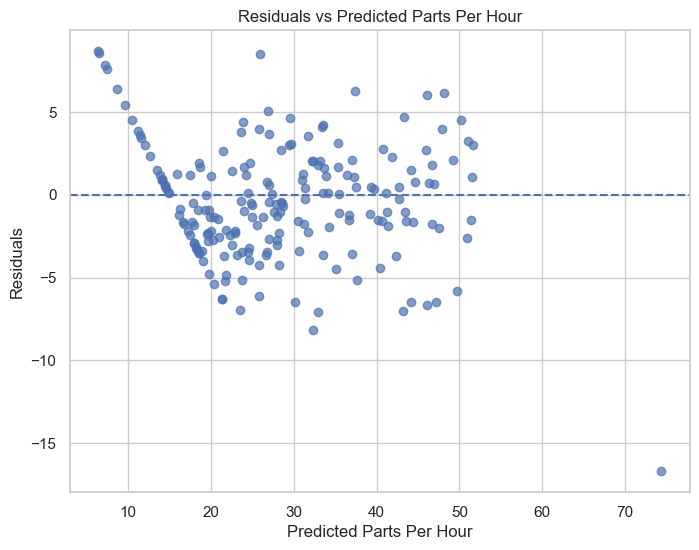

In [40]:
# Residuals vs Predicted Values

plt.figure(figsize=(8, 6))

plt.scatter(y_pred, residuals, alpha=0.7)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Parts Per Hour")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted Parts Per Hour")
plt.show()

### Observation

The residuals are roughly scattered around the zero line without a clear systematic pattern. Most residuals fall within approximately -5 to +5 parts per hour, indicating relatively small prediction errors for most observations.

The absence of a strong visible pattern suggests that the Linear Regression model provides a reasonable fit to the test data.

In [41]:
# Extract feature names after preprocessing
feature_names = model.named_steps["preprocessor"].get_feature_names_out()

# Extract model coefficients
coefficients = model.named_steps["regressor"].coef_

# Create a coefficient table
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Sort by coefficient magnitude
coefficient_table["Absolute_Coefficient"] = (
    coefficient_table["Coefficient"].abs()
)

coefficient_table = coefficient_table.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(coefficient_table)

,Feature,Coefficient,Absolute_Coefficient
10,num__Total_Cycle_Time,-10.059056,10.059056
15,cat__Shift_Night,-3.960544,3.960544
17,cat__Machine_Type_Type_C,-3.920108,3.920108
18,cat__Material_Grade_Premium,3.106103,3.106103
11,num__Efficiency_Score,2.865605,2.865605
3,num__Cooling_Time,2.668843,2.668843
16,cat__Machine_Type_Type_B,-2.421668,2.421668
0,num__Injection_Temperature,2.302566,2.302566
6,num__Machine_Age,-2.201487,2.201487
25,cat__Day_of_Week_Wednesday,1.752058,1.752058


In [42]:
# Create a clean coefficient table for interpretation

coefficient_table_clean = coefficient_table[
    ["Feature", "Coefficient"]
].copy()

coefficient_table_clean["Coefficient"] = (
    coefficient_table_clean["Coefficient"].round(3)
)

display(coefficient_table_clean)

,Feature,Coefficient
10,num__Total_Cycle_Time,-10.059
15,cat__Shift_Night,-3.961
17,cat__Machine_Type_Type_C,-3.920
18,cat__Material_Grade_Premium,3.106
11,num__Efficiency_Score,2.866
3,num__Cooling_Time,2.669
16,cat__Machine_Type_Type_B,-2.422
0,num__Injection_Temperature,2.303
6,num__Machine_Age,-2.201
25,cat__Day_of_Week_Wednesday,1.752


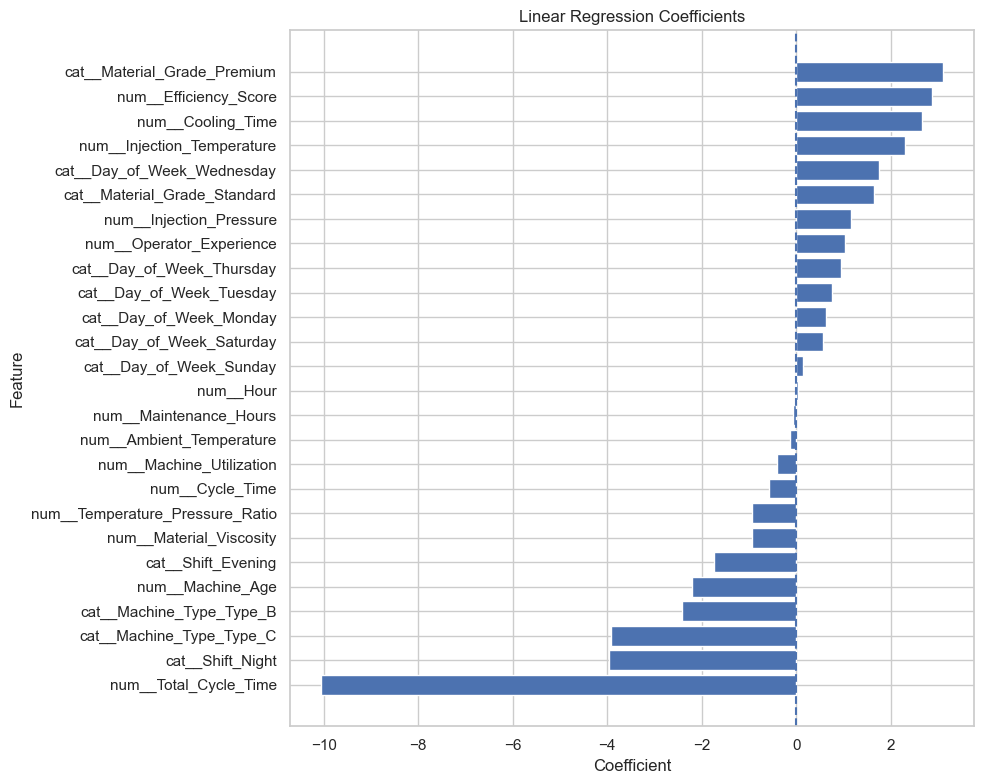

In [43]:
# Plot model coefficients

plot_data = coefficient_table_clean.sort_values("Coefficient")

plt.figure(figsize=(10, 8))

plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"]
)

plt.axvline(0, linestyle="--")

plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Linear Regression Coefficients")
plt.tight_layout()
plt.show()

### Coefficient Interpretation

The coefficient analysis shows that `Total_Cycle_Time` has the largest negative coefficient in the fitted Linear Regression model, while `Material_Grade_Premium`, `Efficiency_Score`, and `Cooling_Time` have notable positive coefficients.

Among the categorical variables, `Shift_Night` and `Machine_Type_Type_C` have negative coefficients relative to their respective reference categories, while `Material_Grade_Premium` has a positive coefficient relative to its reference category.

The numerical features were standardized before modeling, so their coefficients represent the change in predicted `Parts_Per_Hour` associated with a one-standard-deviation change in the corresponding feature, while holding the other model variables constant.

These coefficients represent associations within the fitted model and should not be interpreted as evidence of causation. In addition, the strong correlation between `Cycle_Time` and `Total_Cycle_Time` should be considered when interpreting their individual coefficients.

# 7. Business Insights and Recommendations

### Key Business Insights

Based on the exploratory analysis and Linear Regression results:

- `Cycle_Time` and `Total_Cycle_Time` show strong negative relationships with `Parts_Per_Hour`, indicating that observations with longer cycle durations are generally associated with lower hourly output.
- `Operator_Experience` and `Efficiency_Score` show positive relationships with production output.
- Production output varies across machine types, shifts, and material grades, although there is considerable overlap between groups.
- `Total_Cycle_Time` has the largest negative coefficient in the fitted regression model.
- `Material_Grade_Premium` and `Efficiency_Score` have notable positive coefficients in the fitted model.
- The model's predictions are generally close to the actual production values, with most residuals centered around zero.

These findings can help manufacturing teams identify factors associated with production variation and support further investigation of machine settings, operating conditions, and production practices.

### Recommendations

Based on the analysis, the following recommendations can be considered:

1. **Monitor cycle duration:** Since `Cycle_Time` and `Total_Cycle_Time` have strong negative relationships with production output, production teams should monitor unusually long cycle durations and investigate possible operational causes.

2. **Monitor machine performance:** Differences in output across machine types suggest that machine-level performance should be monitored to identify machines with consistently lower production output.

3. **Review shift-level performance:** Since production output varies across shifts, teams can monitor output by shift and investigate operational differences between shifts.

4. **Track material-grade performance:** Output differences across material grades can be monitored to understand how material selection is associated with production performance.

5. **Use the model for production planning:** The trained Linear Regression model can provide estimated hourly output that may support production planning and capacity monitoring.

6. **Use predictions as a monitoring tool:** Large differences between actual and predicted output can be flagged for further investigation rather than being treated as evidence of a specific cause.